# Лабораторная работа 2. Два класса алгоритмов сортировки

**Опора:** лекции 3–5.

Реализуются **четыре сортировки**:

- пузырьковая — обязательно;
- сортировка подсчётом — обязательно;
- одна из трёх сортировок сравнением: быстрая, слиянием, пирамидальная;
- одна из двух сортировок без сравнений: поразрядная, блочная.

Задача у всех одна: **вход** — список чисел, **выход** — тот же список,
упорядоченный по неубыванию.

Нужно самостоятельно реализовать выбранные алгоритмы, не заменяя их вызовами
готовых сортировок. Конкретный вариант реализации выбирает студент.

In [1]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры массивов:", lk.sizes())

c:\Users\Lenovo\gggg\algosbosborboss\.venv1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Режим: быстрый | размеры массивов: [16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256, 272, 288, 304, 320, 336, 352, 368, 384, 400, 416, 432, 448, 464, 480, 496, 512]


## Задача 1. Пузырьковая сортировка (обязательно)

Соседние элементы сравниваются и переставляются, пока массив не станет
упорядоченным.

Если полный проход не выполнил ни одного обмена, алгоритм должен завершиться.

In [6]:
def bubble_sort(arr):
    """Пузырьковая сортировка."""
    # TODO: реализовать
    n = len(arr)
    for i in range(n):
        s=0
        for j in range(0, n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
                s=1
        if s == 0:
            break
    return arr

In [7]:
lk.check_sort(bubble_sort, "Пузырьковая сортировка")
lk.check_early_exit(bubble_sort, "Досрочный выход")

Пузырьковая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1

## Задача 2. Сортировка подсчётом (обязательно)

Подсчитывается, сколько раз встречается каждый ключ, после чего элементы
раскладываются по местам.

- **Вход:** неотрицательные целые числа.

In [4]:
def counting_sort(arr):
    """Сортировка подсчётом для неотрицательных целых чисел."""
    # TODO: реализовать
    if not arr:
        return arr
    m = max(arr)
    count = [0] * (m + 1)
    for num in arr:
        count[num] += 1
    sorted_arr = []
    for i in range(len(count)):
        sorted_arr.extend([i] * count[i])
    return sorted_arr

In [12]:
lk.check_sort(counting_sort, "Сортировка подсчётом")

Сортировка подсчётом
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 100

## Выбор 1. Сортировка сравнением

Реализовать **одну** из трёх: быструю, слиянием или пирамидальную.

**Быстрая сортировка.** Разделение по опорному элементу. Способ выбора
опорного элемента определяет студент.

**Сортировка слиянием.** Разделение пополам и слияние упорядоченных частей.

**Пирамидальная сортировка.** Реализацию разделить на три функции:

- `_sift_down(arr, start, size)` восстанавливает свойство max-heap в поддереве;
- `_build_max_heap(arr)` строит max-heap снизу вверх;
- `heap_sort(arr)` сначала строит кучу, затем последовательно извлекает максимум.

In [24]:
def quick_sort(arr):
    """Быстрая сортировка."""
    # TODO: реализовать, если выбрана быстрая сортировка
    if len(arr) <= 1:
        return arr
    pivot = arr[len(arr) // 2]
    left = [x for x in arr if x < pivot]
    middle = [x for x in arr if x == pivot]
    right = [x for x in arr if x > pivot]
    return quick_sort(left) + middle + quick_sort(right)


In [25]:
lk.check_sort(quick_sort, "Быстрая сортировка", optional=True)

Быстрая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1000,

In [20]:
def merge_sort(arr):
    """Сортировка слиянием."""
    # TODO: реализовать, если выбрана сортировка слиянием
    raise NotImplementedError("merge_sort")

In [21]:
lk.check_sort(merge_sort, "Сортировка слиянием", optional=True)

Сортировка слиянием: вариант не выбран, тесты пропущены


In [26]:
def _sift_down(arr, start, size):
    """Восстановить свойство max-heap в поддереве с корнем start."""
    # TODO: реализовать просеивание вниз
    raise NotImplementedError("_sift_down")


def _build_max_heap(arr):
    """Построить max-heap снизу вверх."""
    # TODO: реализовать построение кучи
    raise NotImplementedError("_build_max_heap")


def heap_sort(arr):
    """Пирамидальная сортировка с предварительным построением max-heap."""
    # TODO: построить кучу и последовательно извлечь максимумы
    raise NotImplementedError("heap_sort")

In [27]:
lk.check_sort(heap_sort, "Пирамидальная сортировка", optional=True)

Пирамидальная сортировка: вариант не выбран, тесты пропущены


## Выбор 2. Сортировка без сравнений

Реализовать **одну** из двух.

**Поразрядная сортировка.** Обработка чисел по разрядам. Конкретную схему
выбирает студент; результат должен быть упорядочен по неубыванию.

- **Вход:** неотрицательные целые числа.

In [8]:
def radix_sort(arr):
    """Поразрядная сортировка для неотрицательных целых чисел."""
    # TODO: реализовать, если выбрана поразрядная сортировка
    if not arr:
        return arr
    maxi=max(arr)
    a=1
    while maxi//a>0:
        b=[[] for _ in range(10)]
        for i in arr:
            b[i//a%10].append(i)
        arr=[]
        for i in b:
            arr+=i
        a*=10
    return arr

In [9]:
lk.check_sort(radix_sort, "Поразрядная сортировка", optional=True)

Поразрядная сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1

**Блочная сортировка.** Значения распределяются по блокам, каждый блок
сортируется отдельно, после чего блоки соединяются по порядку.

- **Вход:** вещественные числа из полуинтервала `[0, 1)`.

In [10]:
def bucket_sort(arr):
    """Блочная сортировка вещественных чисел из [0, 1)."""
    # TODO: реализовать, если выбрана блочная сортировка
    raise NotImplementedError("bucket_sort")

In [11]:
lk.check_sort(bucket_sort, "Блочная сортировка", floats=True, optional=True)

Блочная сортировка: вариант не выбран, тесты пропущены


## Набор реализованных сортировок

Дальше всё считается по тем реализациям, которые действительно написаны.

In [28]:
INT_SORTS = lk.implemented_sorts({
    "пузырьковая": bubble_sort,
    "подсчётом": counting_sort,
    "быстрая": quick_sort,
    "слиянием": merge_sort,
    "пирамидальная": heap_sort,
    "поразрядная": radix_sort,
})
FLOAT_SORTS = lk.implemented_sorts({"блочная": bucket_sort}, floats=True)

print("В экспериментах участвуют:", ", ".join([*INT_SORTS, *FLOAT_SORTS]))

В экспериментах участвуют: пузырьковая, подсчётом, быстрая, поразрядная


In [29]:
sorting = lk.sorting_table(
    INT_SORTS, FLOAT_SORTS, samples=5, repeats=5,
)

Размер входа: все метрики: 100%|██████████| 640/640 [00:04<00:00, 137.26опыт/s, Размер входа; поразрядная; Случайный; n=512; вход 5/5]


## Эксперимент 1. Все сортировки вместе

Случайный вход одного и того же набора значений для всех сортировок.

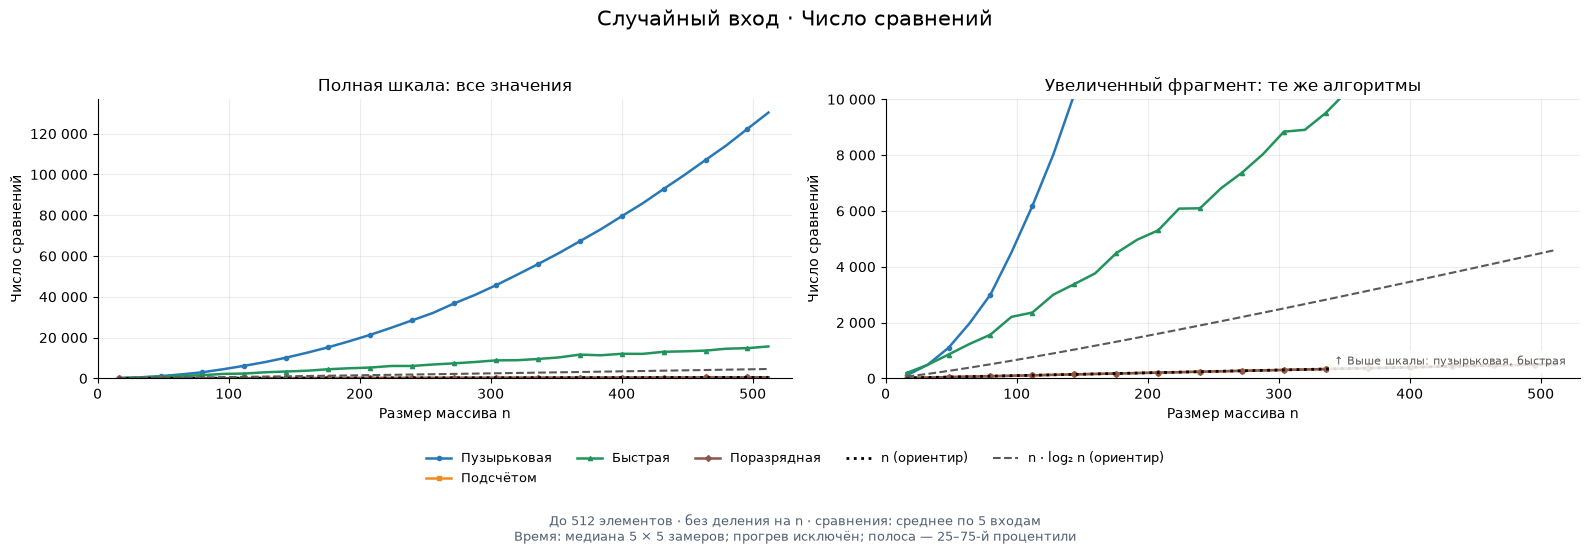

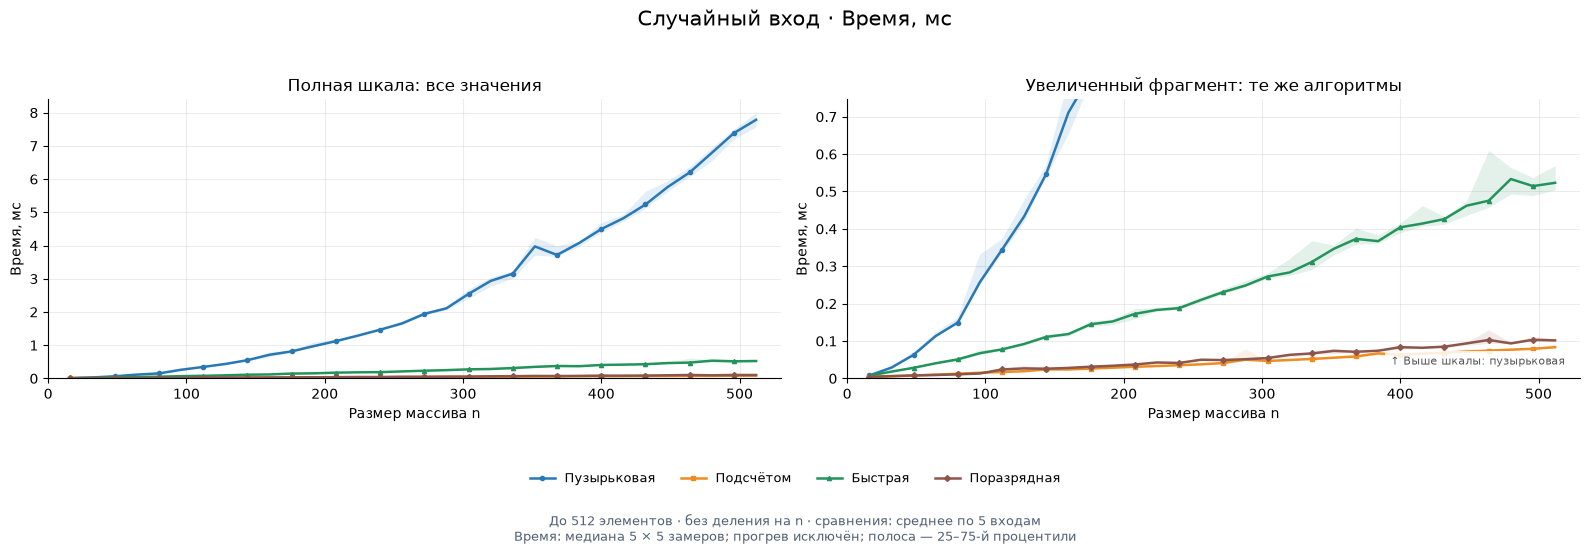

In [30]:
lk.plot_overview(sorting);

## Эксперимент 2. Пространство ключей

Размер массива зафиксирован: `n = 512`. Меняется размер пространства ключей
`k`: элементы случайно выбираются из полуинтервала `[0, k)`. В каждый вход
добавляется ключ `k - 1`, поэтому фактический диапазон не сужается случайно.
Блочная сортировка получает те же ключи, нормированные в диапазон `[0, 1)`.

Результаты разделены по типу алгоритмов:

- для сортировок на сравнениях верхний ряд показывает число сравнений между
  элементами, нижний — время;
- для сортировок, основанных на распределении, верхний ряд показывает число
  выполненных шагов циклов в коде алгоритма и его вспомогательных функций,
  нижний — время.

Один шаг цикла не равен одной машинной операции. Новый счётчик нужен для
сравнения формы зависимостей от `k`, а не абсолютной скорости разных
реализаций.

In [31]:
keyspace = lk.keyspace_table(
    INT_SORTS, FLOAT_SORTS, n=512, samples=5, repeats=5,
)

Пространство ключей: время и работа: 100%|██████████| 260/260 [00:17<00:00, 14.52опыт/s, Пространство ключей; поразрядная; k = 1048576; k=1048576; вход 5/5]


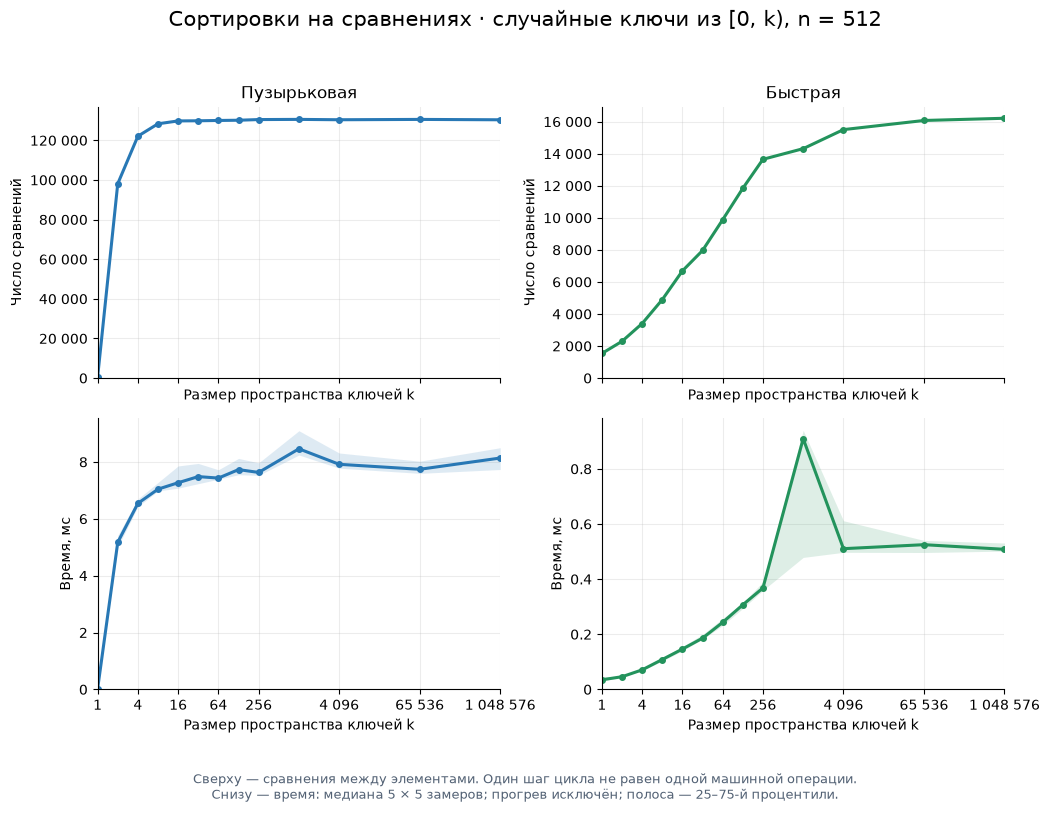

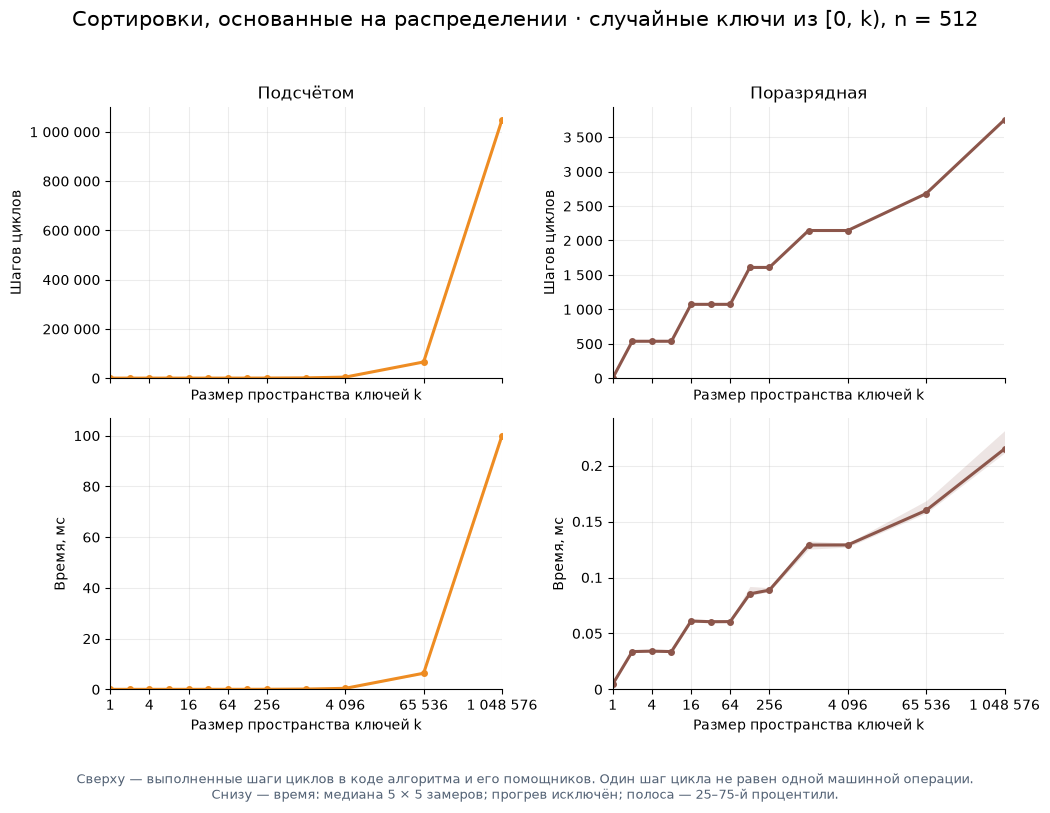

In [32]:
lk.plot_keyspace(keyspace);

## Самостоятельные выводы

Сформулируйте выводы по своим графикам и объясните их устройством реализаций.

1. Почему при увеличении `n` пузырьковая сортировка начинает заметно уступать
   выбранной сортировке сравнением? Какие части алгоритмов определяют форму их
   кривых?
2. Почему сортировки подсчётом, поразрядная и блочная могут обходиться без
   `n log n` сравнений? Какие ограничения на входные данные позволяют им это
   делать?
3. Что особенного происходит при `k = 1`, когда все элементы равны? Какие
   алгоритмы могут завершать отдельные этапы раньше, а какие продолжают
   выполнять почти всю предусмотренную работу?
4. Как повторяющиеся ключи влияют на выбранную сортировку сравнением: на обмены
   пузырьковой сортировки, разбиение быстрой сортировки, слияние или
   восстановление кучи?
5. Если выбрана поразрядная сортировка, почему изменение времени связано с
   числом разрядов? Если выбрана блочная — как распределение элементов по
   блокам влияет на стоимость внутренней сортировки?
6. Какие различия на графиках следуют из общей идеи алгоритма, а какие могут
   измениться при другом выборе опорного элемента, условии досрочного выхода
   или способе сортировки блоков?